# **Project Report - 11**

# **Bachelor of Computer Applications (BCA)**

#**Semester – V**

####**Sub**: Deep Learning ####

####**Topic:**  Handwritten Digit Classification Using CNN ####


####**Submitted By** ####

####**Name:** Pragathi BR ####

####**Reg no:** 2411021240037 ####

####**Date of Submission:** 20/10/2026 ####

####**Faculty Name:** Nagasri. P ####

## **Objective**

To build and train a Convolutional Neural Network (CNN) model to classify handwritten digits from 0 to 9 using the MNIST dataset. The model will be evaluated using accuracy, a confusion matrix, a classification report, and sample predictions.



## **Introduction**

Handwritten digit classification is an image classification problem in deep learning. Different people write the same digit in different styles, making automatic recognition challenging.

The MNIST dataset contains grayscale images of handwritten digits from 0 to 9. A Convolutional Neural Network (CNN) can automatically learn features such as edges, curves, and shapes from images.

In this project, the MNIST dataset is loaded and preprocessed, a CNN model is built and trained, and its performance is evaluated using different classification metrics.



## **Task 1: Load and Preprocess the MNIST Dataset**

### **Theory**

The MNIST dataset contains 70,000 handwritten digit images:

- 60,000 training images.
- 10,000 testing images.
- Each image is 28 × 28 pixels.
- The dataset contains 10 classes representing digits 0 to 9.

Preprocessing prepares the images for the CNN model. It includes loading the dataset, displaying sample images, normalizing pixel values, and reshaping the images into the required input format.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully.")

TensorFlow Version: 2.21.0
Libraries imported successfully.


In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)



### **Explanation**

The MNIST dataset is loaded using TensorFlow Keras. The dataset is divided into training and testing sets.

- `x_train` contains training images.
- `y_train` contains training labels.
- `x_test` contains testing images.
- `y_test` contains testing labels.

The training set contains 60,000 images, and the testing set contains 10,000 images.


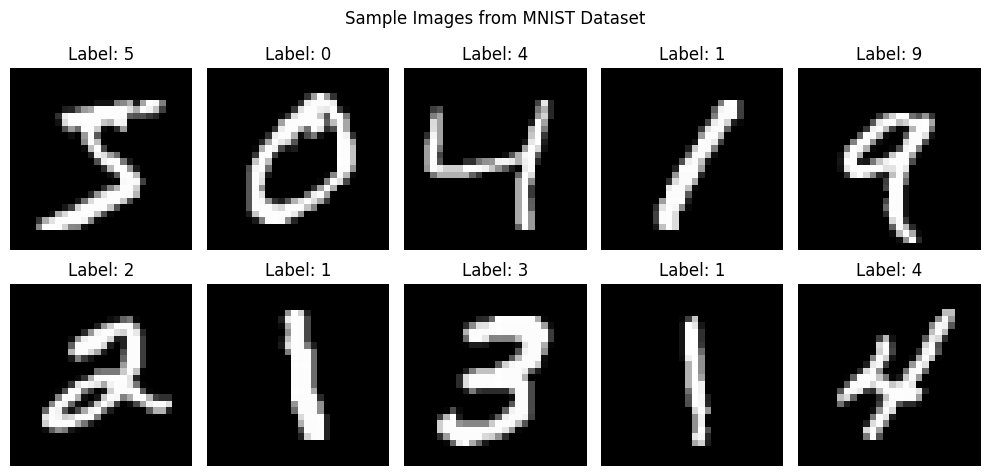

In [3]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Sample Images from MNIST Dataset")
plt.tight_layout()
plt.show()


### **Explanation**

The sample images are displayed using Matplotlib. Each image shows a handwritten digit in grayscale, along with its actual label.

This helps us understand the image format and the different handwriting styles present in the dataset.


In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0



### **Explanation**

The original pixel values range from 0 to 255. Dividing each pixel value by 255 converts the values into the range 0 to 1.

Normalization helps the model train more efficiently by keeping input values within a consistent range.


In [5]:
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)



### **Explanation**

CNN models expect image data in the format `(number of images, height, width, channels)`.

Since MNIST images are grayscale, each image has one channel. Therefore, the images are reshaped to `(28, 28, 1)`.

### **Result of Task 1**

The MNIST dataset was successfully loaded, visualized, normalized, and reshaped for CNN training.



## **Task 2: Build and Train a Basic CNN Model**

### **Theory**

A Convolutional Neural Network (CNN) is a deep learning model used for image classification.

The model consists of the following layers:

1. **Convolutional Layer:** Extracts features such as edges and curves.
2. **Max Pooling Layer:** Reduces the spatial dimensions of feature maps.
3. **Flatten Layer:** Converts feature maps into a one-dimensional vector.
4. **Dense Layer:** Learns patterns for classification.
5. **Output Layer:** Contains 10 neurons representing digits from 0 to 9.

The ReLU activation function helps the hidden layers learn nonlinear patterns, while softmax produces class probabilities.


In [7]:
model = Sequential([
    Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu",
        input_shape=(28, 28, 1)
    ),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       692,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)


### **Explanation**

- `Conv2D` uses 32 filters to extract image features.
- `MaxPooling2D` reduces the feature-map dimensions.
- `Flatten` converts the feature maps into a vector.
- `Dense(128)` learns useful patterns using 128 neurons.
- `Dense(10)` produces probabilities for the ten digit classes.

The model summary displays the layers, output shapes, and trainable parameters.


In [8]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully.")

CNN model compiled successfully.



### **Explanation**

The model is compiled before training.

- **Adam optimizer:** Updates the model weights to reduce errors.
- **Sparse categorical cross-entropy:** Calculates classification loss for integer labels.
- **Accuracy:** Measures the proportion of correctly classified images.


In [9]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 29s 34ms/step - accuracy: 0.9434 - loss: 0.1935 - val_accuracy: 0.9800 - val_loss: 0.0769
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 32ms/step - accuracy: 0.9807 - loss: 0.0648 - val_accuracy: 0.9822 - val_loss: 0.0615
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 27s 32ms/step - accuracy: 0.9864 - loss: 0.0429 - val_accuracy: 0.9873 - val_loss: 0.0529
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 27s 31ms/step - accuracy: 0.9907 - loss: 0.0304 - val_accuracy: 0.9870 - val_loss: 0.0547
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 32ms/step - accuracy: 0.9931 - loss: 0.0209 - val_accuracy: 0.9890 - val_loss: 0.0508



### **Explanation**

The CNN model is trained using the training dataset.

- `epochs=5` means the model processes the training data five times.
- `batch_size=64` means the model trains on batches of 64 images.
- `validation_split=0.1` reserves 10% of the training data for validation.
- `history` stores the training and validation accuracy and loss values.

During training, the model learns patterns that help it identify handwritten digits.


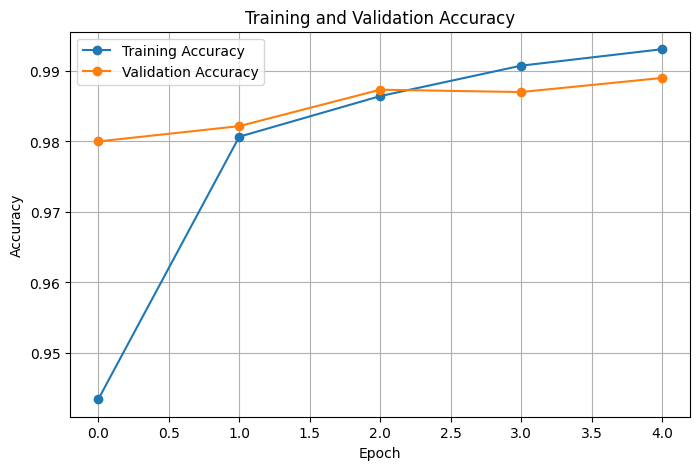

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


### **Explanation**

The graph compares training accuracy and validation accuracy over five epochs.

Training accuracy measures performance on training data, while validation accuracy measures performance on the validation subset. Increasing accuracy generally indicates that the model is learning useful patterns.


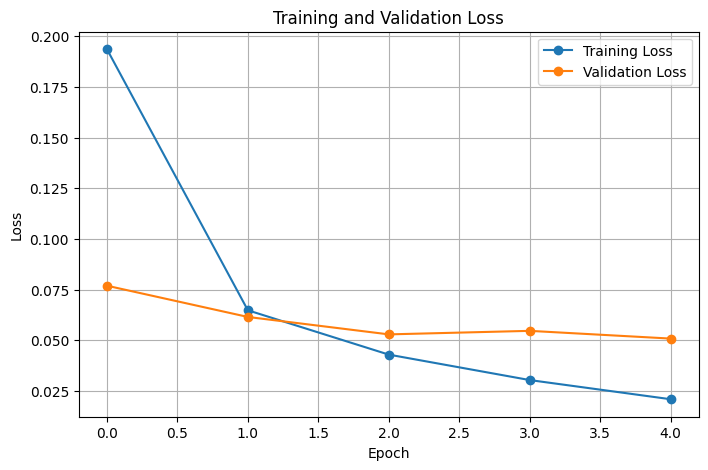

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


### **Explanation**

The graph shows how training loss and validation loss change during training.

Loss measures the difference between the predicted outputs and the actual labels. A decreasing loss generally indicates improvement. If validation loss increases while training loss decreases, the model may be overfitting.

### **Result of Task 2**

The CNN model was successfully built, compiled, and trained using the MNIST dataset. Training and validation performance were visualized using accuracy and loss graphs.



## **Task 3: Evaluate the Model**

### **Theory**

Model evaluation measures how effectively the trained CNN classifies unseen handwritten digit images.

The model is evaluated using the following methods:

- **Accuracy:** Measures the proportion of correct predictions.
- **Confusion Matrix:** Shows correct and incorrect classifications for each digit.
- **Classification Report:** Displays precision, recall, F1-score, and support.
- **Sample Predictions:** Compares actual digits with predicted digits.


In [12]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.0457
Test Accuracy: 98.56%



### **Explanation**

The model is evaluated using the 10,000 test images that were not used during training.

Test accuracy indicates how well the CNN classifies unseen images. Test loss measures the classification error on the test dataset.


In [13]:
y_prob = model.predict(x_test, verbose=0)

y_pred = np.argmax(y_prob, axis=1)

print("Actual labels:   ", y_test[:10])
print("Predicted labels:", y_pred[:10])

Actual labels:    [7 2 1 0 4 1 4 9 5 9]
Predicted labels: [7 2 1 0 4 1 4 9 5 9]



### **Explanation**

The model generates probabilities for each of the ten digit classes. The `argmax()` function selects the class with the highest probability as the predicted digit.

The actual labels and predicted labels can be compared to check the model's predictions.


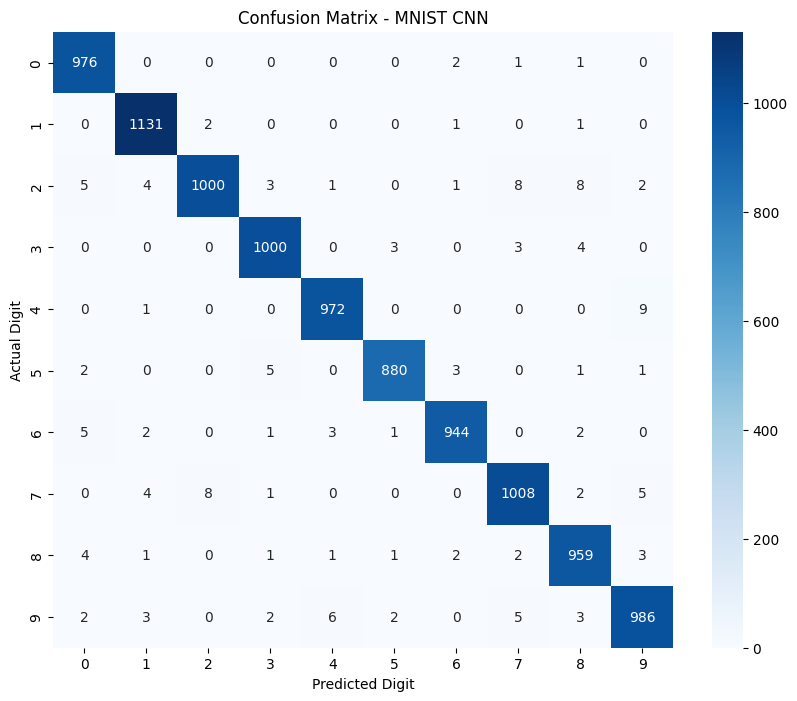

In [14]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("Confusion Matrix - MNIST CNN")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.show()


### **Explanation**

The confusion matrix compares actual digit labels with predicted digit labels.

- Rows represent actual digits.
- Columns represent predicted digits.
- Diagonal values represent correct predictions.
- Off-diagonal values represent misclassified images.

The confusion matrix helps identify which digits the model frequently confuses with other digits.


In [15]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(10)),
        target_names=[str(i) for i in range(10)],
        digits=4,
        zero_division=0
    )
)

Classification Report:

              precision    recall  f1-score   support

           0     0.9819    0.9959    0.9889       980
           1     0.9869    0.9965    0.9917      1135
           2     0.9901    0.9690    0.9794      1032
           3     0.9872    0.9901    0.9886      1010
           4     0.9888    0.9898    0.9893       982
           5     0.9921    0.9865    0.9893       892
           6     0.9906    0.9854    0.9880       958
           7     0.9815    0.9805    0.9810      1028
           8     0.9776    0.9846    0.9811       974
           9     0.9801    0.9772    0.9787      1009

    accuracy                         0.9856     10000
   macro avg     0.9857    0.9856    0.9856     10000
weighted avg     0.9856    0.9856    0.9856     10000




### **Explanation**

The classification report provides the following metrics for each digit:

- **Precision:** The proportion of predicted instances of a digit that are correct.
- **Recall:** The proportion of actual instances of a digit that are correctly identified.
- **F1-score:** The harmonic mean of precision and recall.
- **Support:** The number of actual test images belonging to each digit.

The report also includes macro average and weighted average, which summarize performance across all ten classes.


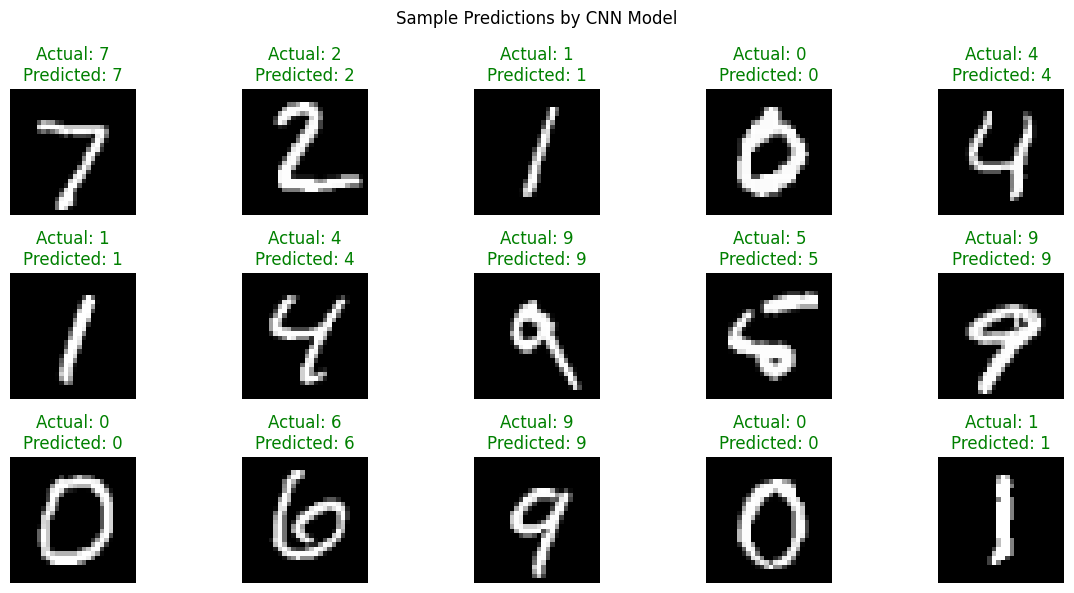

In [16]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(x_test[i].squeeze(), cmap="gray")

    actual = y_test[i]
    predicted = y_pred[i]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color="green" if actual == predicted else "red"
    )

    plt.axis("off")

plt.suptitle("Sample Predictions by CNN Model")
plt.tight_layout()
plt.show()


### **Explanation**

The model predicts the digits for 15 test images.

Each image displays its actual label and predicted label. Green indicates a correct prediction, while red indicates an incorrect prediction.

This visualization provides a simple way to observe the classification results.


In [17]:
cm_without_diagonal = cm.copy()
np.fill_diagonal(cm_without_diagonal, 0)

actual_digit, predicted_digit = np.unravel_index(
    np.argmax(cm_without_diagonal),
    cm_without_diagonal.shape
)

print("Most frequent misclassification:")
print("Actual digit:", actual_digit)
print("Predicted digit:", predicted_digit)
print(
    "Number of misclassified images:",
    cm[actual_digit, predicted_digit]
)

Most frequent misclassification:
Actual digit: 4
Predicted digit: 9
Number of misclassified images: 9



### **Explanation**

This code identifies the largest off-diagonal value in the confusion matrix. It shows which actual digit was most frequently predicted as another digit.

This analysis helps us understand the types of mistakes made by the CNN model.

### **Result of Task 3**

The trained CNN model was evaluated using test accuracy, a confusion matrix, a classification report, and sample predictions. These evaluation methods help measure the model's performance and identify frequently misclassified digits.



## **Overall Result**

A Convolutional Neural Network was developed and trained to classify handwritten digits using the MNIST dataset. The images were preprocessed, and the CNN learned image features through convolutional and pooling layers.

The model was evaluated using test accuracy, a confusion matrix, a classification report, and sample predictions. The confusion matrix helped identify misclassified digits, while the classification report provided precision, recall, and F1-score for each class.



## **Conclusion**

In this project, a Convolutional Neural Network (CNN) was developed to classify handwritten digits using the MNIST dataset. The dataset was loaded, normalized, and reshaped before training the model.

The CNN model was built using convolutional, max-pooling, flatten, and dense layers. It was trained using the Adam optimizer and sparse categorical cross-entropy loss function.

The model was evaluated using test accuracy, a confusion matrix, a classification report, and sample predictions. The confusion matrix helped identify frequently misclassified digits, while precision, recall, and F1-score provided detailed performance measurements.

Thus, the project demonstrates how CNNs can automatically learn image features and perform handwritten digit classification.
